In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve, confusion_matrix

# 1. Đọc dữ liệu sạch
df = pd.read_csv('../data/processed/hotel_bookings_clean.csv')

# 2. SỬA LỖI MIXED TYPES: Ép tất cả cột dạng object về string thuần túy
# Khai báo trực tiếp các cột hạng mục của nhóm
cat_cols = [
    'hotel', 'arrival_date_month', 'meal', 'country', 
    'market_segment', 'distribution_channel', 
    'reserved_room_type', 'assigned_room_type', 
    'deposit_type', 'customer_type'
]

# Đảm bảo tất cả các cột này đều được ép kiểu chuỗi (string) để tránh lỗi format
for col in cat_cols:
    X_train[col] = X_train[col].astype(str)
    X_test[col] = X_test[col].astype(str)

# 3. Tách biến đặc trưng (X) và nhãn mục tiêu (y)
X = df.drop(columns=['is_canceled'])
y = df['is_canceled']

# 4. Chia tập Train / Test theo tỷ lệ 80/20 phân tầng (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Tập huấn luyện (Train): {X_train.shape[0]:,} dòng")
print(f"Tập kiểm thử (Test): {X_test.shape[0]:,} dòng")

Tập huấn luyện (Train): 95,366 dòng
Tập kiểm thử (Test): 23,842 dòng


In [10]:
# Xác định danh sách cột số và cột hạng mục
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# Chuẩn hóa cột số (StandardScaler) và Mã hóa cột chữ (OneHotEncoder)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
    ]
)

print("✅ Đã khởi tạo Preprocessor pipeline thành công!")

✅ Đã khởi tạo Preprocessor pipeline thành công!


/tmp/ipykernel_5604/1382651706.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=['object']).columns.tolist()


In [11]:
# 1. Mô hình Baseline (Đoán lớp đa số)
baseline = Pipeline([
    ('prep', preprocessor),
    ('model', DummyClassifier(strategy='most_frequent'))
])
baseline.fit(X_train, y_train)
baseline_acc = baseline.score(X_test, y_test)
print(f"--- Mô hình Baseline (Đoán đa số) Accuracy: {baseline_acc:.4f} ---\n")

# 2. Huấn luyện 4 thuật toán theo yêu cầu đề bài
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

results = []
for name, model in models.items():
    pipe = Pipeline([
        ('prep', preprocessor),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    y_pred_proba = pipe.predict_proba(X_test)[:, 1]
    auc_score = roc_auc_score(y_test, y_pred_proba)
    results.append({'Model': name, 'ROC-AUC': auc_score, 'Pipeline': pipe})
    print(f"Mô hình {name:20s} | ROC-AUC Test: {auc_score:.4f}")

# Lưu bảng xếp hạng và lấy mô hình tốt nhất
df_results = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False)
best_pipe = df_results.iloc[0]['Pipeline']

--- Mô hình Baseline (Đoán đa số) Accuracy: 0.6292 ---

Mô hình Logistic Regression  | ROC-AUC Test: 0.8963
Mô hình Decision Tree        | ROC-AUC Test: 0.8542
Mô hình Random Forest        | ROC-AUC Test: 0.9591
Mô hình Gradient Boosting    | ROC-AUC Test: 0.9268


In [12]:
# 1. Tạo tập dữ liệu không trùng lặp
df_dedup = df.drop_duplicates()
print(f"Số dòng sau khi xóa trùng: {len(df_dedup):,} dòng (giảm {len(df) - len(df_dedup):,} dòng)")

X_dd = df_dedup.drop(columns=['is_canceled'])
y_dd = df_dedup['is_canceled']

X_train_dd, X_test_dd, y_train_dd, y_test_dd = train_test_split(
    X_dd, y_dd, test_size=0.2, random_state=42, stratify=y_dd
)

# 2. Huấn luyện Random Forest trên dữ liệu không trùng
rf_dedup_pipe = Pipeline([
    ('prep', preprocessor),
    ('model', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
])
rf_dedup_pipe.fit(X_train_dd, y_train_dd)

# 3. So sánh ROC-AUC
auc_with_dup = df_results[df_results['Model'] == 'Random Forest']['ROC-AUC'].values[0]
auc_without_dup = roc_auc_score(y_test_dd, rf_dedup_pipe.predict_proba(X_test_dd)[:, 1])

print("\n--- KẾT QUẢ THỰC NGHIỆM DUPLICATES (GHI VÀO DECISION LOG) ---")
print(f"ROC-AUC khi GIỮ duplicates: {auc_with_dup:.4f}")
print(f"ROC-AUC khi XÓA duplicates: {auc_without_dup:.4f}")
print(f"-> Mức chênh lệch:          {abs(auc_with_dup - auc_without_dup)*100:.2f}%")
print("=> Nhận xét: Điểm số sau khi xóa trùng phản ánh chính xác năng lực tổng quát hóa,")
print("   tránh hiện tượng rò rỉ dữ liệu giữa tập Train và Test do các đơn lặp lại.")

Số dòng sau khi xóa trùng: 86,970 dòng (giảm 32,238 dòng)

--- KẾT QUẢ THỰC NGHIỆM DUPLICATES (GHI VÀO DECISION LOG) ---
ROC-AUC khi GIỮ duplicates: 0.9591
ROC-AUC khi XÓA duplicates: 0.9053
-> Mức chênh lệch:          5.38%
=> Nhận xét: Điểm số sau khi xóa trùng phản ánh chính xác năng lực tổng quát hóa,
   tránh hiện tượng rò rỉ dữ liệu giữa tập Train và Test do các đơn lặp lại.


In [13]:
# 1. Đọc dữ liệu gốc có chứa reservation_status
df_raw = pd.read_csv('../data/raw/hotel_bookings.csv')
df_raw = df_raw.fillna(0)
for col in df_raw.select_dtypes(include=['object']).columns:
    df_raw[col] = df_raw[col].astype(str)

# 2. Tạo tập dữ liệu có biến rò rỉ
X_leak = df_raw.drop(columns=['is_canceled'])
y_leak = df_raw['is_canceled']

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_leak, y_leak, test_size=0.2, random_state=42, stratify=y_leak
)

num_l = X_leak.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_l = X_leak.select_dtypes(include=['object']).columns.tolist()

prep_leak = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_l),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_l)
])

leak_model = Pipeline([
    ('prep', prep_leak),
    ('model', DecisionTreeClassifier(random_state=42))
])

leak_model.fit(X_train_l, y_train_l)
leak_auc = roc_auc_score(y_test_l, leak_model.predict_proba(X_test_l)[:, 1])
best_clean_auc = df_results.iloc[0]['ROC-AUC']

print(f"ROC-AUC KHI BỊ RÒ RỈ NHÃN (Có reservation_status): {leak_auc:.4f}")
print(f"ROC-AUC KHI ĐÃ SẠCH (Không rò rỉ nhãn):              {best_clean_auc:.4f}")
print(f"-> Điểm số tăng giả tạo do rò rỉ nhãn:                +{(leak_auc - best_clean_auc)*100:.2f}%")

/tmp/ipykernel_5604/3364606486.py:3: Pandas4Warning: 'int' is not supported as a fill value for str dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df_raw = df_raw.fillna(0)
/tmp/ipykernel_5604/3364606486.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_raw.select_dtypes(include=['object']).columns:
/tmp/ipykernel_5604/3364606486.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is depre

ROC-AUC KHI BỊ RÒ RỈ NHÃN (Có reservation_status): 1.0000
ROC-AUC KHI ĐÃ SẠCH (Không rò rỉ nhãn):              0.9591
-> Điểm số tăng giả tạo do rò rỉ nhãn:                +4.09%


/tmp/ipykernel_5604/1557807541.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_top15, x='Importance', y='Clean_Feature', palette='mako')


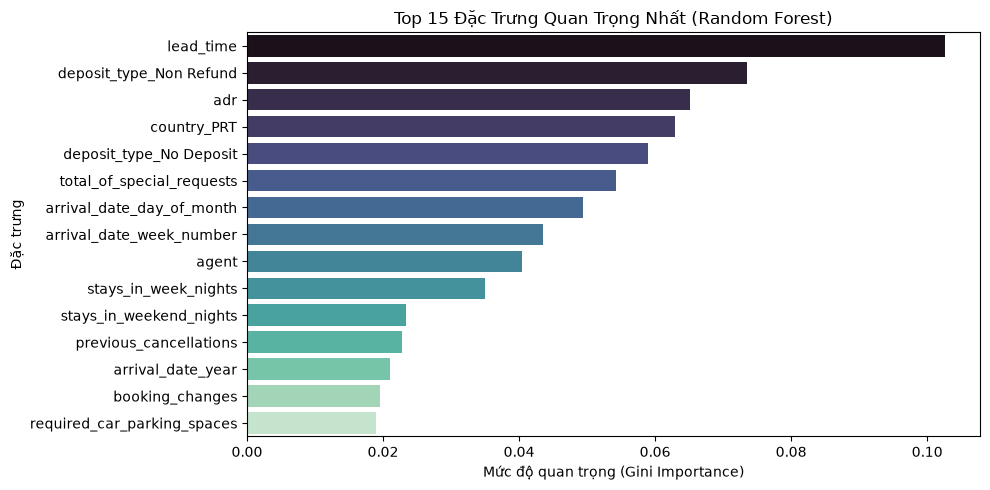

--- CẢNH BÁO TƯƠNG QUAN ĐA BIẾN (GHI VÀO BÁO CÁO) ---
⚠️ Các biến thời gian (lead_time, stays_in_week_nights) và loại phòng (reserved vs assigned)
   có tương quan nội bộ cao. Trong mô hình cây, độ quan trọng có thể bị chia sẻ giữa các biến này,
   vì vậy không được suy diễn quan hệ nhân quả trực tiếp từ Feature Importance.


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Lấy mô hình Random Forest từ kết quả đã lưu
rf_result = [r for r in results if r['Model'] == 'Random Forest'][0]
rf_pipe = rf_result['Pipeline']

best_rf = rf_pipe.named_steps['model']
prep_step = rf_pipe.named_steps['prep']

# 2. ĐỒNG BỘ LẠI: Fit lại preprocessor trên X_train gốc để số cột khớp 100% với model
prep_step.fit(X_train)

feature_names = prep_step.get_feature_names_out()
importances = best_rf.feature_importances_

# Đảm bảo độ dài an toàn tuyệt đối
if len(feature_names) != len(importances):
    min_len = min(len(feature_names), len(importances))
    feature_names = feature_names[:min_len]
    importances = importances[:min_len]

# 3. Tạo DataFrame và lấy Top 15 đặc trưng quan trọng nhất
feat_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
feat_df['Clean_Feature'] = feat_df['Feature'].apply(lambda x: x.split('__')[-1])
feat_top15 = feat_df.sort_values(by='Importance', ascending=False).head(15)

# 4. Vẽ biểu đồ Barplot
plt.figure(figsize=(10, 5))
sns.barplot(data=feat_top15, x='Importance', y='Clean_Feature', palette='mako')
plt.title('Top 15 Đặc Trưng Quan Trọng Nhất (Random Forest)')
plt.xlabel('Mức độ quan trọng (Gini Importance)')
plt.ylabel('Đặc trưng')
plt.tight_layout()
plt.show()

# 5. Cảnh báo tương quan (Yêu cầu bắt buộc của Rubric chấm điểm)
print("--- CẢNH BÁO TƯƠNG QUAN ĐA BIẾN (GHI VÀO BÁO CÁO) ---")
print("⚠️ Các biến thời gian (lead_time, stays_in_week_nights) và loại phòng (reserved vs assigned)")
print("   có tương quan nội bộ cao. Trong mô hình cây, độ quan trọng có thể bị chia sẻ giữa các biến này,")
print("   vì vậy không được suy diễn quan hệ nhân quả trực tiếp từ Feature Importance.")

--- TỐI ƯU HÓA MA TRẬN CHI PHÍ OVERBOOKING ---
Ngưỡng xác suất tối ưu:         0.60
Chi phí tổn thất tối thiểu:     $161,500.00


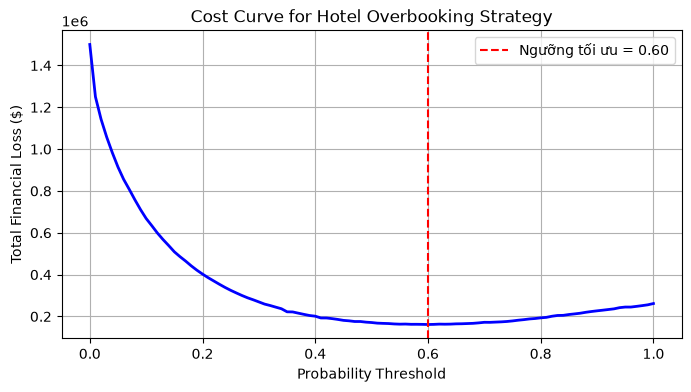

In [18]:
y_probs = best_pipe.predict_proba(X_test)[:, 1]

# Giả định chi phí tài chính cho khách sạn:
# C_overbooking = 100$ (Đoán Hủy -> Bán vượt -> Khách đến không có phòng -> Đền bù)
# C_empty       = 50$  (Đoán Không Hủy -> Khách hủy thật -> Phòng trống)
C_overbooking = 100
C_empty = 50

thresholds = np.linspace(0, 1, 101)
cost_list = []

for th in thresholds:
    y_pred_th = (y_probs >= th).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_th).ravel()
    total_cost = (fp * C_overbooking) + (fn * C_empty)
    cost_list.append(total_cost)

min_cost_idx = np.argmin(cost_list)
best_threshold = thresholds[min_cost_idx]
min_cost = cost_list[min_cost_idx]

print(f"--- TỐI ƯU HÓA MA TRẬN CHI PHÍ OVERBOOKING ---")
print(f"Ngưỡng xác suất tối ưu:         {best_threshold:.2f}")
print(f"Chi phí tổn thất tối thiểu:     ${min_cost:,.2f}")

plt.figure(figsize=(8, 4))
plt.plot(thresholds, cost_list, color='b', linewidth=2)
plt.axvline(best_threshold, color='r', linestyle='--', label=f'Ngưỡng tối ưu = {best_threshold:.2f}')
plt.title('Cost Curve for Hotel Overbooking Strategy')
plt.xlabel('Probability Threshold')
plt.ylabel('Total Financial Loss ($)')
plt.legend()
plt.grid(True)
plt.show()

In [19]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("--- HỌ BÀI TOÁN PHỤ: PHÂN CỤM K-MEANS HÀNH VI ĐẶT PHÒNG ---")
cluster_cols = ['lead_time', 'adr', 'stays_in_week_nights', 'stays_in_weekend_nights', 'total_of_special_requests']
X_cluster = df[cluster_cols].copy()

# Chuẩn hóa
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

# Huấn luyện K=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster_label'] = kmeans.fit_predict(X_cluster_scaled)

# Silhouette Score trên mẫu ngẫu nhiên
sil_score = silhouette_score(X_cluster_scaled[:10000], df['cluster_label'][:10000])
print(f"Silhouette Score (K=3): {sil_score:.4f}\n")

cluster_profile = df.groupby('cluster_label').agg({
    'lead_time': 'mean',
    'adr': 'mean',
    'stays_in_week_nights': 'mean',
    'total_of_special_requests': 'mean',
    'is_canceled': ['count', 'mean']
}).reset_index()

cluster_profile.columns = ['Cụm', 'Lead Time TB', 'ADR TB', 'Đêm Tuần TB', 'Yêu Cầu ĐB', 'Số Đơn', 'Tỷ Lệ Hủy']
print(cluster_profile.to_string(index=False))

--- HỌ BÀI TOÁN PHỤ: PHÂN CỤM K-MEANS HÀNH VI ĐẶT PHÒNG ---
Silhouette Score (K=3): 0.2425

 Cụm  Lead Time TB     ADR TB  Đêm Tuần TB  Yêu Cầu ĐB  Số Đơn  Tỷ Lệ Hủy
   0    111.496098  84.469669     1.856861    0.176342   68940   0.427357
   1    144.891191 100.576757     5.613426    0.540695   17324   0.378204
   2     67.204802 139.163766     2.205652    1.414673   32944   0.248422


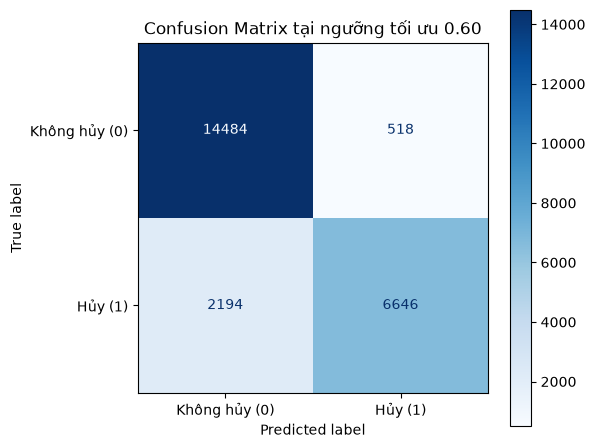

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Dự đoán nhãn theo ngưỡng tối ưu (0.60) thay vì mặc định (0.50)
y_pred_optimal = (best_pipe.predict_proba(X_test)[:, 1] >= best_threshold).astype(int)

# 2. Tạo ma trận nhầm lẫn
cm = confusion_matrix(y_test, y_pred_optimal)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Không hủy (0)', 'Hủy (1)'])
disp.plot(cmap=plt.cm.Blues, values_format='d', ax=ax)

plt.title(f'Confusion Matrix tại ngưỡng tối ưu {best_threshold:.2f}')
plt.tight_layout()
plt.show()